<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/03_DDoS_DoS_Detection/HybridQNN_DDoSAndroidMalware_Sridevi2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-classical neural network (HQCNN, dressed quantum circuit) for SDN DDoS and Android malware detection: Sridevi et al. (2025) step by step

This notebook re-implements, runs and checks the experiments of

> S. Sridevi, B. Indira, S. Geetha, S. Balachandran, G. Kar and S. Kharbanda,
> "Unified hybrid quantum classical neural network framework for detecting distributed denial of service and Android mobile malware attacks",
> *EPJ Quantum Technology* 12, 77 (2025). DOI [10.1140/epjqt/s40507-025-00380-z](https://doi.org/10.1140/epjqt/s40507-025-00380-z)

The paper builds **one pipeline for two security tasks**: every network-flow record (SDN DDoS data) or Android-app feature vector (CCCS-CIC-AndMal2020 static data)
is turned into a small **wavelet scaleogram image**, a 2-D CNN and a **linear discriminant analysis (LDA)** squeeze the image to a handful of numbers, and these numbers go through a
**dressed quantum circuit**: a classical dense layer, a 2-qubit PennyLane circuit (angle embedding, one trainable entangling layer, Pauli-Z read-out) and a classical dense head.
The paper reports 99.86 % accuracy for DDoS detection (binary HQCNN, Table 7) and 93.56 / 94.38 / 95.13 % for 15 / 14 / 12 Android malware classes (Table 12).

**What the notebook does.**
1. Downloads the real **SDN DDoS Attack Dataset** (Ahuja et al., Mendeley Data, 104,345 flows, the data set of the paper) and checks its hash.
2. Draws the real data (class distribution, 2-D projections of real flows coloured by their ground-truth label).
3. Rebuilds the paper's pre-processing: min-max scaling, one-level biorthogonal DWT, Morlet CWT scaleogram (12 x 12 x 3 image), 2-D CNN feature extractor (Table 6), LDA.
4. Builds the **HQCNN** (variant 1 of the paper: basic angle embedding), draws the circuits that are executed and trains it with Adam, batch size 32.
5. Trains classical baselines on exactly the same inputs: the paper's 2-D CNN, the same dressed network **without** the quantum node, random forest and RBF-SVM.
6. Re-creates the paper's Table 7 (three circuit variants), Table 8 (k-fold cross-validation vs the CNN), Table 9 (number of layers and shots on the Lightning simulator), Fig. 10 (loss curves) and Fig. 11 (confusion matrices),
   adds one ablation (log-scaled inputs) and prints a verdict per claim.
7. For the **Android half** the notebook contains the same pipeline ready to run, but the data set (CCCS-CIC-AndMal2020 static features) is only distributed through a personal registration form of the
   Canadian Institute for Cybersecurity and is not available on any open mirror. It is therefore stated as **cannot be checked** (exact files below); nothing is substituted.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` is a class demo (smaller sample, few epochs, 3 folds, one seed); `FAST_MODE = False` follows the paper's budgets
(100 epochs, 10 folds) as far as a CPU simulator allows; the configuration cell lists both. No quantum hardware, account or token is needed for the SDN data.
If you ever point the notebook at a gated Hugging Face data set, add your own token as a Colab Secret named `HF_TOKEN`; it is read only from `os.environ["HF_TOKEN"]` or Colab Secrets and never printed or stored.

**What you get at the end.** A table "paper vs this notebook" with a verdict for each reported number, the circuits, the scaleograms and the reproduced figures.

## The paper in one page

**Problem.** Software-defined networks (SDN) are exposed to DDoS floods, and mobile devices to Android malware. The authors want one lightweight quantum-enhanced pipeline for both.

**Decision.** DDoS: binary (benign / attack). Android: multi-class (15, 14 or 12 malware categories, Table 4 of the paper). Metrics: accuracy, precision, recall, F1 (Eqs. 11-14).

**Pipeline (Section 4, Figs. 1-9, Tables 5-6).**
* *Min-max normalisation* (Eq. 1) of each flow vector. *Discrete wavelet transform* with a biorthogonal wavelet (one level for SDN, three levels with `bior6.8` for Android), keep the approximation coefficients.
  *Continuous wavelet transform* with a Morlet wavelet turns them into a 2-D **scaleogram image**: 12 x 12 x 3 for the 24 SDN features, 250 x 250 x 3 for the 9,503 Android features (Table 5).
* *CNN feature extractor* (Table 6): two blocks Conv2D(3x3, 128 then 64 filters) + ReLU + MaxPool(2x2), flatten, Dense(64) + ReLU.
* *LDA* reduces the features to `n - 1` discriminant directions (one for the binary task); Fig. 4 shows a "concatenated LDA-reduced 2-D feature vector".
* *Dressed quantum circuit (DQC)*: classical input layer `C(2->2)` + ReLU, **quantum node** = angle embedding `RX(q_k * pi/2)` on 2 qubits, `BasicEntanglerLayers`-type variational layer with `RY(w)` rotations and an entangler,
  Pauli-Z read-out (Eqs. 6-9), then three Dense(64) layers and one output neuron (Eq. 10). Three embedding variants were tried (Figs. 6-8); variant 1 (basic angle embedding) is best.
* *Training*: Adam, batch size 32, 100 epochs, 70 % / 30 % split, 10-fold cross-validation, grid-searched 64 neurons; PennyLane `lightning.qubit` and AWS Braket (SV1 simulator, Oxford "Lucy" and Rigetti "Aspen-M-3" QPUs), 500 or 1000 shots.

**Data.** SDN DDoS Attack Dataset (Table 3): 63,561 benign + 40,784 attack flows, 24 features, a balanced subset of 2,000 + 2,000 flows. CCCS-CIC-AndMal2020 static (Table 4): 9,503 features, 800 apps per category.

**Claims to check.**

| Claim | Paper value |
|---|---|
| Binary HQCNN, variant 1, `n_layers=1`, `n_shots=1000` (Table 7) | accuracy 99.86, precision 99.85, recall 100, F1 99.88 |
| Variant 2 / variant 3 (Table 7) | accuracy 97.43 / 97.12 |
| 10-fold CV (Table 8) | HQCNN mean 99.86 % (every fold above 99 %), 2-D CNN mean 86.80 % (86.17 to 87.48) |
| Layers x shots on Lightning (Table 9) | 99.65 to 99.96 % for `n_layers` 1..3 and `n_shots` 500 / 1000 |
| Real QPUs (Table 10) | HQCNN 99.56 % on Lucy and Aspen-M-3, CNN 91 % |
| Confusion matrix (Fig. 11) | HQCNN no false positives / negatives; CNN misclassifies 19 % of normal traffic |
| Android 15 / 14 / 12 classes (Tables 11-12) | accuracy 93.56 / 94.38 / 95.13 %; 2-D CNN mean accuracy 78.94 % on 12 classes |

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| SDN data | SDN DDoS Attack Dataset, IEEE Dataport (Ahuja et al.) | the same data set from its Mendeley Data record (DOI 10.17632/jxpfjc64kr.1, CC BY 4.0), `dataset_sdn.csv`, 104,345 rows; sha-256 checked; 506 rows with a missing rate dropped |
| Sample | 2,000 benign + 2,000 attack flows (Table 3) | the same, seeded random sample (`FAST_MODE`: 600 + 600) |
| 24 features | not listed | 19 numeric columns + one-hot Protocol (3) + last octet of `src` and `dst` (the addresses are `10.0.0.x`) = 24. `label` is the target |
| Split / CV | 70 % / 30 %; 10-fold CV, 100 epochs | stratified 70 / 30 held-out test split for Tables 7, 9, 10 and Fig. 11; 10-fold stratified CV on the 4,000 flows for Table 8 with **every transform re-fitted inside each fold** |
| Min-max | Eq. 1 | `MinMaxScaler` fitted on the training split only; test values clipped to [0, 1] |
| DWT | one level, "biorthogonal" (wavelet not named for SDN) | `bior6.8`, one level, symmetric padding, approximation coefficients (20 values) |
| CWT / image | Morlet CWT, 12 x 12 x 3 | Morlet (`morl`), 12 scales, |coefficient| resampled to 12 time steps by linear interpolation, colour-mapped with `viridis` (fixed range from the training split) to 3 channels |
| CNN | Table 6 | exactly Table 6 (Conv128-ReLU-Pool-Conv64-ReLU-Pool-Flatten-Dense64) in PyTorch (the paper used TensorFlow); Adam 1e-3, batch 32; a sigmoid output on top for the CNN baseline |
| LDA "concatenated 2-D vector" | Fig. 4, details not given | track A: LDA of the 64 CNN features; track B: LDA of the flattened scaleogram pixels; each gives one component, concatenated into a 2-D vector. Both LDAs are fitted on the training split |
| Quantum node | Figs. 6-9; 2 qubits, 1 layer, `RX(q pi/2)` embedding, `RY` variational layer, Pauli-Z | PennyLane `RX(q_k pi/2)` + `BasicEntanglerLayers(rotation=RY)` + `<Z_0>, <Z_1>`; weights uniform in [0, 2 pi] |
| Variants 2 and 3 | Figs. 7-8 (images, not machine-readable) | **our reading**: variant 2 = `RX, RY, RZ` of the same angle on each qubit; variant 3 = `H, RZ, RX` per qubit. They may differ from the paper's drawings |
| Dense layers | `C(2->2)` input, three Dense(64) + 1 output | `Linear(2,2)`+ReLU -> quantum node -> `Linear(2,64)`-ReLU-`Linear(64,64)`-ReLU-`Linear(64,64)`-ReLU-`Linear(64,1)` + sigmoid |
| Optimiser | Adam, batch 32 (learning rate not given) | Adam, learning rate 1e-2 for the HQCNN heads, 1e-3 for the CNN; binary cross-entropy |
| Simulator | `lightning.qubit`, shots 500 / 1000 | training with the exact differentiable `default.qubit` (back-propagation, no sampling noise); shot sampling evaluated on `lightning.qubit` afterwards (Table 9); equivalence of both devices is asserted |
| Real QPUs, AWS SV1 | Lucy, Aspen-M-3 (retired), SV1 | **cannot be checked** here (no hardware, no AWS Braket) |
| Heavy-tailed features | plain min-max (Eq. 1) | main run: plain min-max as in the paper. **Ablation (not in the paper)**: signed `log1p` before min-max, reported separately in section 7 |
| Android data | CCCS-CIC-AndMal2020 static, 9,503 features | **cannot be downloaded without a personal registration form**; the code path is included and runs if you supply the file (`ANDMAL_PATH`); image size is a configurable 64 x 64 instead of 250 x 250 (memory) |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and seaborn.
# The pip line runs on Colab (or wherever PennyLane / PyWavelets are missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or any(importlib.util.find_spec(m) is None for m in ("pennylane", "pywt")):
    %pip install -q "pennylane==0.45.1" "PyWavelets==1.8.0" requests
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane and PyWavelets already present; skipping pip install.")

pennylane and PyWavelets already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True              # True: class demo in about 10 minutes. False: paper budgets (100 epochs, 10 folds), see FULL_BUDGET below.
SEED      = 42                # master seed (CHOICE: the paper gives none)

# --- budgets -------------------------------------------------------------------------------------------------------
if FAST_MODE:
    N_PER_CLASS   = 600       # flows per class sampled from the 104,345 (paper: 2,000)
    EPOCHS        = 12        # paper: 100
    EPOCHS_CNN    = 8         # epochs of the 2-D CNN (feature extractor and baseline)
    K_FOLDS       = 3         # paper: 10
    EPOCHS_CV     = 6         # epochs per fold (HQCNN and CNN)
    SEEDS         = [42]      # repeats of the held-out experiment
    EPOCHS_GRID   = 8         # epochs for each cell of the layers x shots grid (Table 9)
else:
    N_PER_CLASS   = 2000      # Table 3
    EPOCHS        = 100       # Section 5.2
    EPOCHS_CNN    = 30
    K_FOLDS       = 10        # Section 5.2
    EPOCHS_CV     = 30
    SEEDS         = [42, 43, 44]
    EPOCHS_GRID   = 30
FULL_BUDGET = "N_PER_CLASS=2000, EPOCHS=100, EPOCHS_CNN=30, K_FOLDS=10, EPOCHS_CV=30, SEEDS=[42,43,44], EPOCHS_GRID=30"

TEST_SIZE  = 0.30             # Section 5.2: 70 % train / 30 % test
BATCH      = 32               # Section 5.2
LR_CNN, LR_HQ = 1e-3, 1e-2    # CHOICE: learning rates are not given
N_QUBITS   = 2                # C(2->2) input layer, two qubits (Fig. 6)
N_LAYERS   = 1                # paper's final choice
SHOTS_LIST = [500, 1000]      # Tables 7 and 9
SCALES     = 12               # CWT scales = image height (Table 5: 12 x 12 x 3)
IMG        = 12               # image width
WAVELET    = "bior6.8"        # CHOICE for SDN (the paper names bior6.8 for Android only)

DATA_DIR   = "sridevi2025_data"                       # cache folder
SDN_URL    = "https://data.mendeley.com/public-files/datasets/jxpfjc64kr/files/5b57518c-c0fa-4cd9-bc11-e01bd5a363f4/file_downloaded"
SDN_SHA256 = "e0d9fa511e57b849bf15fbd1d0ac91a83bbd4ad55706eadffe077de6246e4dd3"
SDN_PATH   = None                                     # or the path of an uploaded dataset_sdn.csv

# Android half (optional): path of a CCCS-CIC-AndMal2020 *static* CSV that YOU obtained from the CIC registration form
ANDMAL_PATH      = None          # e.g. "/content/andmal2020_static.csv"
ANDMAL_LABEL_COL = "Category"    # CHOICE: name of the category column in your file (check df.columns)
ANDMAL_N_PER_CLASS = 800         # Table 4
ANDMAL_IMG       = 64            # CHOICE: 64 x 64 instead of 250 x 250 to fit in memory
ANDMAL_LEVELS    = 3             # DWT levels (Table 5)
ANDMAL_QUBITS    = 4             # CHOICE: Fig. 9 does not give the width of the multi-class circuit
IBM_TOKEN  = ""                  # unused: the experiment needs no IBM hardware
print(f"FAST_MODE={FAST_MODE}  N_PER_CLASS={N_PER_CLASS}  EPOCHS={EPOCHS}  K_FOLDS={K_FOLDS}  SEEDS={SEEDS}")
print("full budget:", FULL_BUDGET)

FAST_MODE=True  N_PER_CLASS=600  EPOCHS=12  K_FOLDS=3  SEEDS=[42]
full budget: N_PER_CLASS=2000, EPOCHS=100, EPOCHS_CNN=30, K_FOLDS=10, EPOCHS_CV=30, SEEDS=[42,43,44], EPOCHS_GRID=30


In [3]:
import os, time, warnings, hashlib, io
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import pennylane as qml
import pywt, sklearn, requests
from matplotlib import cm
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")

def set_all_seeds(seed):
    np.random.seed(seed); torch.manual_seed(seed)

set_all_seeds(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| PyWavelets", pywt.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | PyWavelets 1.8.0 | matplotlib 3.11.2


## 1. Data: the SDN DDoS Attack Dataset

The data set was produced by Ahuja, Singal and Mukhopadhyay with the Mininet emulator and a Ryu controller: ten random topologies, benign TCP / UDP / ICMP traffic and malicious TCP-SYN, UDP and ICMP floods.
Flow statistics are read from the switches every 30 s (packet and byte counts, durations, rates, ports ...). Each row is one flow record, the last column `label` is `0` (benign) or `1` (DDoS attack).
It is open (CC BY 4.0): no token is needed. The cell below nevertheless shows how a Hugging Face token would be resolved if you point the notebook at a gated data set.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (optional here: the SDN data are open)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

if SDN_PATH is None:
    SDN_PATH = os.path.join(DATA_DIR, "dataset_sdn.csv")
    if not os.path.exists(SDN_PATH):
        r = requests.get(SDN_URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=180); r.raise_for_status()
        with open(SDN_PATH, "wb") as fh: fh.write(r.content)
    with open(SDN_PATH, "rb") as fh:
        print("dataset_sdn.csv sha-256 matches the Mendeley record:", hashlib.sha256(fh.read()).hexdigest() == SDN_SHA256)
SDN_RAW = pd.read_csv(SDN_PATH)
print("SDN DDoS Attack Dataset as downloaded:", SDN_RAW.shape, "| rows with a missing value (rx_kbps / tot_kbps):", int(SDN_RAW.isna().any(axis=1).sum()))
SDN_RAW = SDN_RAW.dropna().reset_index(drop=True)      # CHOICE: drop the 506 rows (0.5 %) with missing rates
print("after dropping them:", SDN_RAW.shape, "| paper Table 3: 104,345 rows (63,561 normal, 40,784 attack)")

def sdn_features(df):
    """24 numeric features: 19 numeric columns + one-hot Protocol (3) + last octet of src and dst (CHOICE, see table above)."""
    X = df.drop(columns=["label", "src", "dst", "Protocol"]).astype(float).copy()
    for p in ["ICMP", "TCP", "UDP"]:
        X["proto_" + p] = (df["Protocol"] == p).astype(float)
    X["src_octet"] = df["src"].str.split(".").str[-1].astype(float)
    X["dst_octet"] = df["dst"].str.split(".").str[-1].astype(float)
    return X

SDN_X = sdn_features(SDN_RAW)
SDN_Y = SDN_RAW["label"].values.astype(int)
SDN_PROTO = SDN_RAW["Protocol"].values
FEATURES = list(SDN_X.columns)
print("feature matrix:", SDN_X.shape, "(paper: 24 features)")

dataset_sdn.csv sha-256 matches the Mendeley record: True


SDN DDoS Attack Dataset as downloaded: (104345, 23) | rows with a missing value (rx_kbps / tot_kbps): 506
after dropping them: (103839, 23) | paper Table 3: 104,345 rows (63,561 normal, 40,784 attack)


feature matrix: (103839, 24) (paper: 24 features)


In [5]:
def balanced_sample(y, n_per_class, seed):
    r = np.random.default_rng(seed)
    return np.concatenate([r.choice(np.where(y == c)[0], n_per_class, replace=False) for c in (0, 1)])

def split_for_seed(seed):
    idx = balanced_sample(SDN_Y, N_PER_CLASS, seed)
    tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=SDN_Y[idx], random_state=seed)
    return tr, te

TR_IDX, TE_IDX = split_for_seed(SEED)
Xtr, Xte = SDN_X.values[TR_IDX], SDN_X.values[TE_IDX]
ytr, yte = SDN_Y[TR_IDX], SDN_Y[TE_IDX]
print(f"sample: {len(TR_IDX) + len(TE_IDX)} flows -> train {len(TR_IDX)} / test {len(TE_IDX)}; attack share train {ytr.mean():.2f}, test {yte.mean():.2f}")

sample: 1200 flows -> train 840 / test 360; attack share train 0.50, test 0.50


## Dataset Exploration and Visualisation

Everything in this section is drawn from the **real** SDN DDoS flows and their **ground-truth labels** (`0` benign, `1` DDoS attack). Nothing is simulated or relabelled.
The original data set has only these two labels; the protocol (TCP / UDP / ICMP) is used as a second colour code so that the three attack families of the data set (TCP-SYN, UDP and ICMP floods) can be told apart in the plots.
The PCA below is fitted on the **training split only**.

SDN DDoS Attack Dataset (complete rows): (103839, 23)
feature names used (24): ['dt', 'switch', 'pktcount', 'bytecount', 'dur', 'dur_nsec', 'tot_dur', 'flows', 'packetins', 'pktperflow', 'byteperflow', 'pktrate', 'Pairflow', 'port_no', 'tx_bytes', 'rx_bytes', 'tx_kbps', 'rx_kbps', 'tot_kbps', 'proto_ICMP', 'proto_TCP', 'proto_UDP', 'src_octet', 'dst_octet']
original label values and counts (0 = benign, 1 = DDoS attack):
label
benign (0)    63335
attack (1)    40504
protocol x label counts:


label     attack  benign
Protocol                
ICMP        9419   31902
TCP        13866   15570
UDP        17219   15863

sample used here: train (840, 24), test (360, 24); class counts train [420 420], test [180 180]


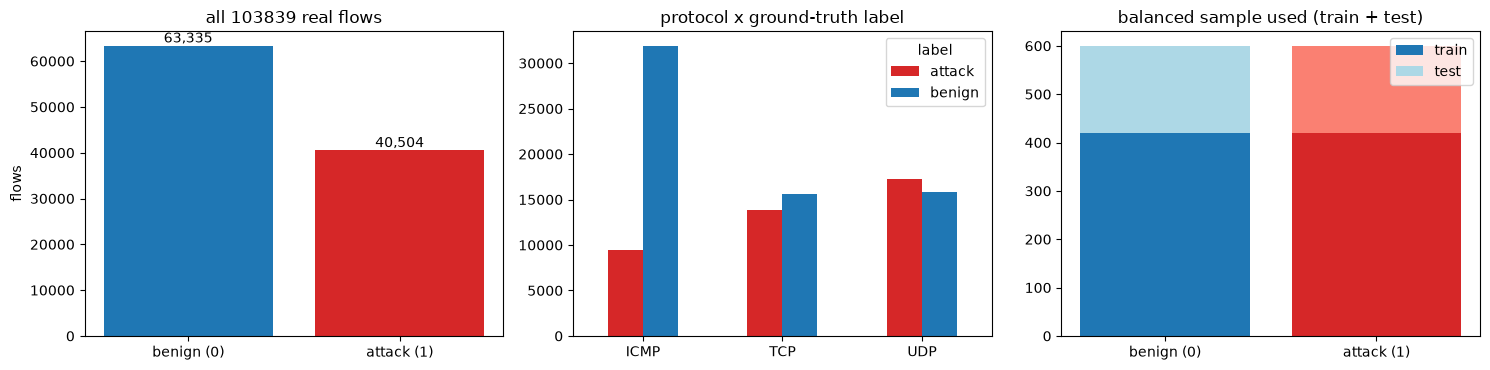

In [6]:
print("SDN DDoS Attack Dataset (complete rows):", SDN_RAW.shape)
print("feature names used (%d):" % len(FEATURES), FEATURES)
print("original label values and counts (0 = benign, 1 = DDoS attack):")
print(SDN_RAW["label"].value_counts().rename({0: "benign (0)", 1: "attack (1)"}).to_string())
print("protocol x label counts:")
print(pd.crosstab(SDN_RAW["Protocol"], SDN_RAW["label"].map({0: "benign", 1: "attack"})).to_string())
print(f"\nsample used here: train {Xtr.shape}, test {Xte.shape}; class counts train {np.bincount(ytr)}, test {np.bincount(yte)}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
vc = SDN_RAW["label"].value_counts().sort_index()
ax[0].bar(["benign (0)", "attack (1)"], vc.values, color=["tab:blue", "tab:red"]); ax[0].set_title("all %d real flows" % len(SDN_RAW)); ax[0].set_ylabel("flows")
for i, v in enumerate(vc.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ct = pd.crosstab(SDN_RAW["Protocol"], SDN_RAW["label"].map({0: "benign", 1: "attack"}))
ct.plot.bar(ax=ax[1], color=["tab:red", "tab:blue"], rot=0); ax[1].set_title("protocol x ground-truth label"); ax[1].set_xlabel("")
ax[2].bar(["benign (0)", "attack (1)"], [np.sum(ytr == 0), np.sum(ytr == 1)], color=["tab:blue", "tab:red"], label="train")
ax[2].bar(["benign (0)", "attack (1)"], [np.sum(yte == 0), np.sum(yte == 1)], bottom=[np.sum(ytr == 0), np.sum(ytr == 1)], color=["lightblue", "salmon"], label="test")
ax[2].set_title("balanced sample used (train + test)"); ax[2].legend()
plt.tight_layout(); plt.show()

explained variance ratio of the 2 components: [0.378 0.216]


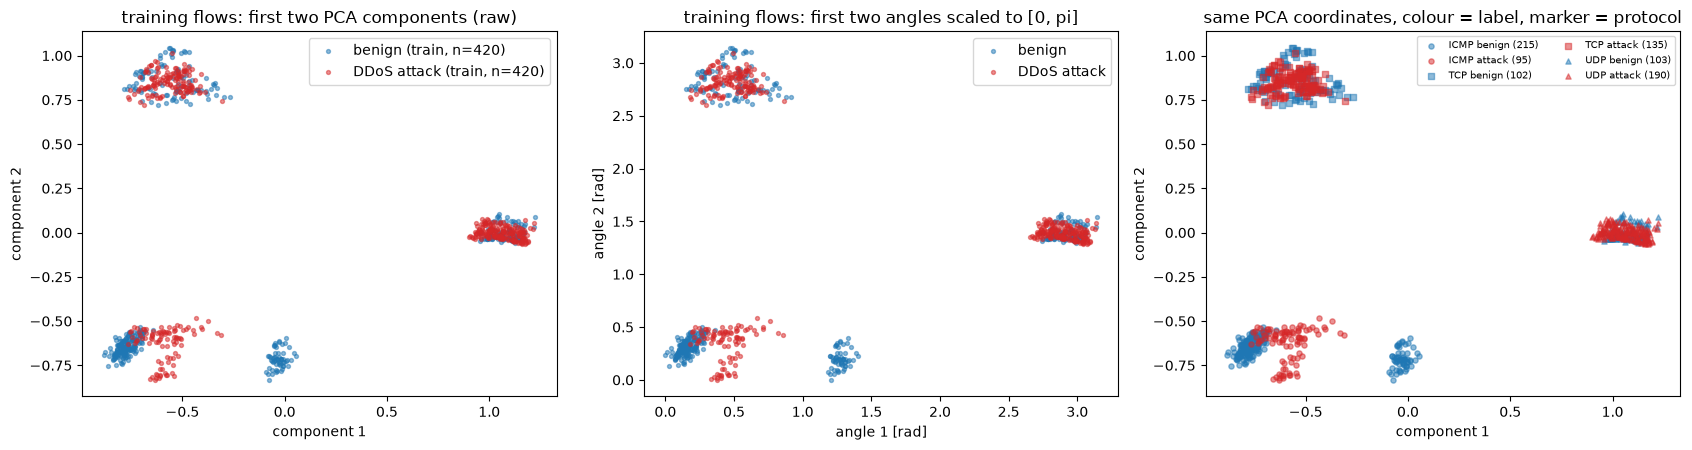

In [7]:
# 2-D scatter of real flows: PCA of the 24 min-max scaled features, fitted on the training split only.
# (1) raw PCA coordinates, (2) the same coordinates scaled to [0, pi] (the range an angle encoding would use).
_sc = MinMaxScaler().fit(Xtr)
_pca = PCA(n_components=2, random_state=SEED).fit(_sc.transform(Xtr))
Ptr, Pte = _pca.transform(_sc.transform(Xtr)), _pca.transform(np.clip(_sc.transform(Xte), 0, 1))
print("explained variance ratio of the 2 components:", np.round(_pca.explained_variance_ratio_, 3))
_ang = MinMaxScaler((0, np.pi)).fit(Ptr)
Atr, Ate = _ang.transform(Ptr), np.clip(_ang.transform(Pte), 0, np.pi)

proto_tr = SDN_PROTO[TR_IDX]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for lab, col, name in [(0, "tab:blue", "benign"), (1, "tab:red", "DDoS attack")]:
    m = ytr == lab
    ax[0].scatter(Ptr[m, 0], Ptr[m, 1], s=8, alpha=0.5, c=col, label=f"{name} (train, n={m.sum()})")
    ax[1].scatter(Atr[m, 0], Atr[m, 1], s=8, alpha=0.5, c=col, label=name)
ax[0].set_title("training flows: first two PCA components (raw)"); ax[1].set_title("training flows: first two angles scaled to [0, pi]")
ax[0].legend(); ax[1].legend()
mk = {"ICMP": "o", "TCP": "s", "UDP": "^"}
for p in ["ICMP", "TCP", "UDP"]:
    for lab, col in [(0, "tab:blue"), (1, "tab:red")]:
        m = (proto_tr == p) & (ytr == lab)
        ax[2].scatter(Ptr[m, 0], Ptr[m, 1], s=14, alpha=0.5, c=col, marker=mk[p], label=f"{p} {'attack' if lab else 'benign'} ({m.sum()})")
ax[2].set_title("same PCA coordinates, colour = label, marker = protocol"); ax[2].legend(fontsize=7, ncol=2)
for a in ax: a.set_xlabel("component 1"); a.set_ylabel("component 2")
ax[1].set_xlabel("angle 1 [rad]"); ax[1].set_ylabel("angle 2 [rad]")
plt.tight_layout(); plt.show()

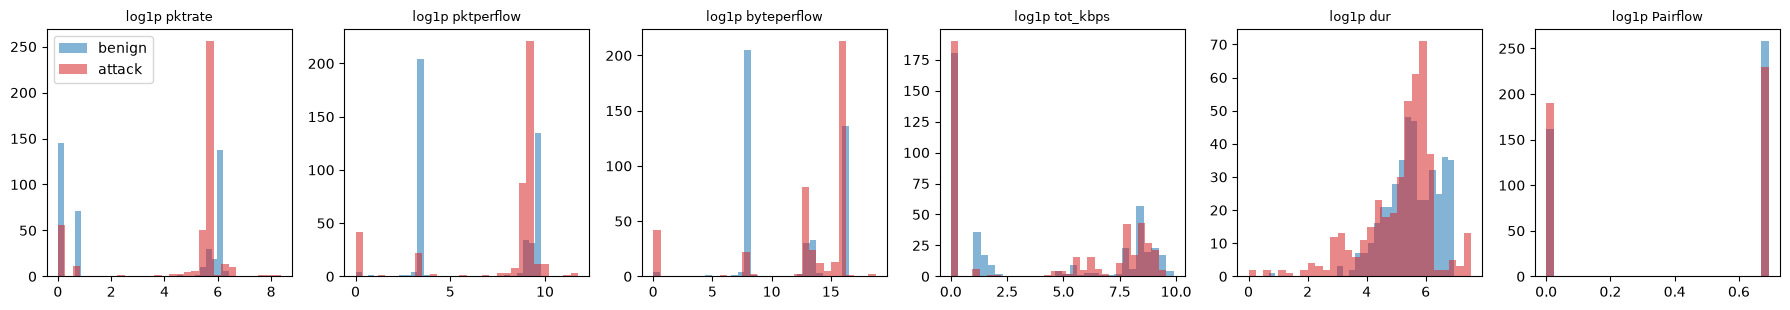

In [8]:
# Feature-wise view: distribution of a few informative features per class (real flows, training split).
cols = ["pktrate", "pktperflow", "byteperflow", "tot_kbps", "dur", "Pairflow"]
fig, ax = plt.subplots(1, len(cols), figsize=(18, 3.2))
for a, c in zip(ax, cols):
    j = FEATURES.index(c)
    for lab, col in [(0, "tab:blue"), (1, "tab:red")]:
        v = Xtr[ytr == lab, j]
        a.hist(np.log1p(np.abs(v)), bins=30, alpha=0.55, color=col, label=("attack" if lab else "benign"))
    a.set_title("log1p " + c, fontsize=9)
ax[0].legend(); plt.tight_layout(); plt.show()

### Android half: data availability

The paper's second data set, **CCCS-CIC-AndMal2020 (static)**, is distributed by the Canadian Institute for Cybersecurity and the Canadian Centre for Cyber Security through a personal registration form
(name, e-mail, organisation, country) on `cicresearch.ca`; I found no open mirror (Hugging Face, Zenodo, GitHub). Filling in the form on someone's behalf is not something a notebook should do, and substituting another Android data set
would not be a reproduction of the paper, so **the Android experiment cannot be run here**. To run it yourself: register at <https://www.unb.ca/cic/datasets/andmal2020.html>, download the *static* feature CSV
(9,503 feature columns plus a category label per app), upload it to Colab and set `ANDMAL_PATH` and `ANDMAL_LABEL_COL` in the configuration cell. Section 8 then runs the same pipeline with a multi-class head.
No Android plots appear in this notebook for that reason.

In [9]:
if ANDMAL_PATH is not None and os.path.exists(ANDMAL_PATH):
    _head = pd.read_csv(ANDMAL_PATH, nrows=5)
    print("AndMal file found:", ANDMAL_PATH, "| columns:", _head.shape[1], "| label column present:", ANDMAL_LABEL_COL in _head.columns)
else:
    print("Android data set: no file supplied (ANDMAL_PATH is None). Needed: the CCCS-CIC-AndMal2020 static feature CSV from the CIC registration form.")

Android data set: no file supplied (ANDMAL_PATH is None). Needed: the CCCS-CIC-AndMal2020 static feature CSV from the CIC registration form.


## 2. Pre-processing: min-max, wavelet transforms, scaleogram images (paper Section 4.1)

1. **Min-max normalisation** (Eq. 1), fitted on the training split.
2. **DWT** with a biorthogonal wavelet, one level: the 24 features become 20 approximation coefficients `cA`.
3. **CWT** of `cA` with a Morlet wavelet and 12 scales gives a 12 x 20 coefficient map; its magnitude is resampled to 12 x 12 and colour-mapped to 3 channels. The picture is the "scaleogram image" of the paper (Fig. 2).

scaleogram images: train (840, 3, 12, 12) test (360, 3, 12, 12) (4.5 s)  | paper Table 5: 12 x 12 x 3


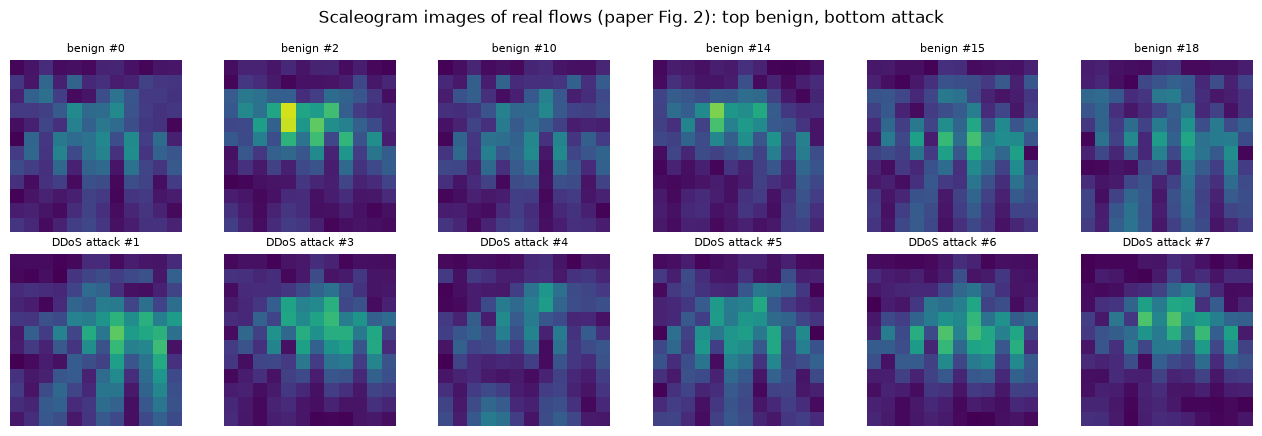

In [10]:
def scaleogram(z, wavelet=WAVELET, level=1, n_scales=SCALES, width=IMG):
    """One min-max scaled feature vector -> |Morlet CWT| of the DWT approximation, resampled to n_scales x width."""
    cA = pywt.wavedec(z, wavelet, level=level, mode="symmetric")[0]
    coef, _ = pywt.cwt(cA, np.arange(1, n_scales + 1), "morl")
    W = np.abs(coef)
    xs = np.linspace(0, W.shape[1] - 1, width)
    return np.stack([np.interp(xs, np.arange(W.shape[1]), row) for row in W]).astype(np.float32)

class ImageMaker:
    """Min-max scaler + scaleogram + fixed colour range, all fitted on the training split only."""
    def __init__(self, **kw): self.kw = kw
    def fit(self, X):
        self.mm = MinMaxScaler().fit(X)
        S = self.raw(X)
        self.lo, self.hi = float(S.min()), float(S.max())
        return self
    def raw(self, X):
        Z = np.clip(self.mm.transform(X), 0, 1)
        return np.stack([scaleogram(z, **self.kw) for z in Z])
    def transform(self, X):
        S = self.raw(X)
        rgb = cm.viridis(np.clip((S - self.lo) / (self.hi - self.lo + 1e-12), 0, 1))[..., :3].astype(np.float32)
        return rgb.transpose(0, 3, 1, 2).copy()          # N x 3 x H x W

t0 = time.time()
IM = ImageMaker().fit(Xtr)
Itr, Ite = IM.transform(Xtr), IM.transform(Xte)
print("scaleogram images: train", Itr.shape, "test", Ite.shape, f"({time.time() - t0:.1f} s)  | paper Table 5: 12 x 12 x 3")

fig, ax = plt.subplots(2, 6, figsize=(13, 4.4))
for r, lab in enumerate([0, 1]):
    ids = np.where(ytr == lab)[0][:6]
    for c, i in enumerate(ids):
        ax[r, c].imshow(Itr[i].transpose(1, 2, 0), interpolation="nearest"); ax[r, c].axis("off")
        ax[r, c].set_title(("benign" if lab == 0 else "DDoS attack") + f" #{i}", fontsize=8)
plt.suptitle("Scaleogram images of real flows (paper Fig. 2): top benign, bottom attack"); plt.tight_layout(); plt.show()

## 3. Classical building blocks: CNN feature extractor and LDA (paper Sections 4.1.3-4.1.4)

The CNN of Table 6 is trained as a classifier on the training images (this is also the paper's "2-D CNN" baseline). Its 64-dimensional penultimate layer is the feature vector.
Two LDA tracks, both fitted on the training split, give the 2-D input of the dressed quantum circuit: track A = LDA of the 64 CNN features, track B = LDA of the flattened scaleogram pixels (one component each, because `n - 1 = 1` for two classes).

2-D CNN baseline (8 epochs, 743 s):  {'acc': 67.5, 'prec': 63.07, 'rec': 84.44, 'f1': 72.21}
LDA 2-D feature vectors: (840, 2) (360, 2)


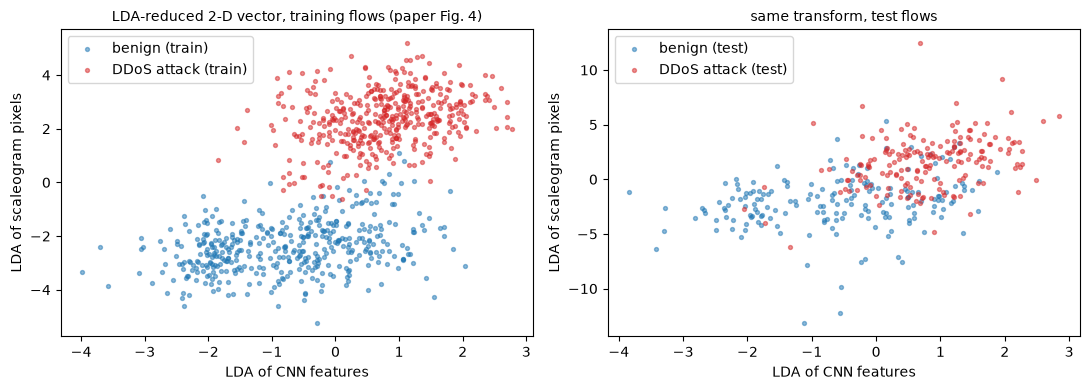

In [11]:
class CNN(nn.Module):
    """Table 6: Conv2D(128,3x3)-ReLU-MaxPool(2)-Conv2D(64,3x3)-ReLU-MaxPool(2)-Flatten-Dense(64)-ReLU (+ output layer for the baseline)."""
    def __init__(self, n_out=1):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(3, 128, 3), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(128, 64, 3), nn.ReLU(), nn.MaxPool2d(2),
                               nn.Flatten(), nn.LazyLinear(64), nn.ReLU())
        self.o = nn.Linear(64, n_out)
    def forward(self, x):
        z = self.o(self.f(x))
        return z.squeeze(-1) if z.shape[-1] == 1 else z

def fit_torch(model, X, y, epochs, lr, batch=BATCH, loss="bce", seed=SEED, log_every=1):
    """Adam + binary (or multi-class) cross-entropy; returns the per-epoch mean training loss."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lf = nn.BCEWithLogitsLoss() if loss == "bce" else nn.CrossEntropyLoss()
    Xt = torch.tensor(X, dtype=torch.float32); yt = torch.tensor(y, dtype=torch.float32 if loss == "bce" else torch.long)
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xt), generator=g); tot = 0.0
        model.train()
        for i in range(0, len(Xt), batch):
            b = perm[i:i + batch]
            opt.zero_grad(); l = lf(model(Xt[b]), yt[b]); l.backward(); opt.step(); tot += l.item() * len(b)
        hist.append(tot / len(Xt))
    model.eval()
    return hist

@torch.no_grad()
def predict_torch(model, X, batch=512):
    model.eval(); out = []
    for i in range(0, len(X), batch):
        out.append(model(torch.tensor(X[i:i + batch], dtype=torch.float32)))
    return torch.cat(out)

@torch.no_grad()
def cnn_features(cnn, I, batch=512):
    cnn.eval()
    return torch.cat([cnn.f(torch.tensor(I[i:i + batch])) for i in range(0, len(I), batch)]).numpy()

def lda_tracks(cnn, Itr, ytr, Ite):
    """Fit both LDA tracks on the training split; return (train, test) feature vectors (n_classes - 1 components per track)."""
    Ftr, Fte = cnn_features(cnn, Itr), cnn_features(cnn, Ite)
    A = LDA(solver="svd").fit(Ftr, ytr)
    B = LDA(solver="svd").fit(Itr.reshape(len(Itr), -1), ytr)
    Ltr = np.c_[A.transform(Ftr), B.transform(Itr.reshape(len(Itr), -1))]
    Lte = np.c_[A.transform(Fte), B.transform(Ite.reshape(len(Ite), -1))]
    return Ltr.astype(np.float32), Lte.astype(np.float32)

def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="binary", pos_label=1, zero_division=0)
    return dict(acc=100 * accuracy_score(y, p), prec=100 * pr, rec=100 * rc, f1=100 * f1)

def build_features(Xa, ya, Xb, seed, epochs_cnn, image_kw=None, n_classes=2):
    """Everything classical, fitted on (Xa, ya) only: min-max -> scaleogram -> CNN (trained) -> two LDA tracks.
    Returns a dict with the images, the trained CNN, its predictions on Xb and the LDA vectors of both splits."""
    set_all_seeds(seed)
    maker = ImageMaker(**(image_kw or {})).fit(Xa)
    Ia, Ib = maker.transform(Xa), maker.transform(Xb)
    cnn = CNN(1 if n_classes == 2 else n_classes); cnn(torch.zeros(1, *Ia.shape[1:]))      # materialise the lazy layer
    t0 = time.time()
    hist = fit_torch(cnn, Ia, ya, epochs_cnn, LR_CNN, seed=seed, loss="bce" if n_classes == 2 else "ce")
    out = predict_torch(cnn, Ib)
    pred = (out > 0).numpy().astype(int) if n_classes == 2 else out.argmax(1).numpy()
    La, Lb = lda_tracks(cnn, Ia, ya, Ib)
    return dict(maker=maker, Ia=Ia, Ib=Ib, cnn=cnn, cnn_pred=pred, cnn_hist=hist, cnn_time=time.time() - t0, La=La, Lb=Lb)

feat = build_features(Xtr, ytr, Xte, SEED, EPOCHS_CNN)
cnn, cnn_pred, CNN_HIST, CNN_TIME = feat["cnn"], feat["cnn_pred"], feat["cnn_hist"], feat["cnn_time"]
Itr, Ite = feat["Ia"], feat["Ib"]
Ltr, Lte = feat["La"], feat["Lb"]
print(f"2-D CNN baseline ({EPOCHS_CNN} epochs, {CNN_TIME:.0f} s): ", {k: round(v, 2) for k, v in metrics(yte, cnn_pred).items()})
print("LDA 2-D feature vectors:", Ltr.shape, Lte.shape)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for lab, col, name in [(0, "tab:blue", "benign"), (1, "tab:red", "DDoS attack")]:
    ax[0].scatter(Ltr[ytr == lab, 0], Ltr[ytr == lab, 1], s=8, alpha=0.5, c=col, label=name + " (train)")
    ax[1].scatter(Lte[yte == lab, 0], Lte[yte == lab, 1], s=8, alpha=0.5, c=col, label=name + " (test)")
for a, t in zip(ax, ["LDA-reduced 2-D vector, training flows (paper Fig. 4)", "same transform, test flows"]):
    a.set_title(t, fontsize=10); a.set_xlabel("LDA of CNN features"); a.set_ylabel("LDA of scaleogram pixels"); a.legend()
plt.tight_layout(); plt.show()

## 4. The dressed quantum circuit (paper Section 4.2, Figs. 6-9)

`HQCNN = Linear(2,2)+ReLU  ->  quantum node  ->  Linear-ReLU x3 (64 neurons)  ->  Linear(1)`.

The **quantum node** (Eq. 6, `QN = A o VQC o M`) acts on two qubits:
* `A` (angle embedding, Eq. 7): `RX(q_k * pi/2)` on qubit `k` (variant 1). Variants 2 and 3 use other embeddings (see the table above for what "our reading" means).
* `VQC` (Eq. 8): `n_layers` PennyLane `BasicEntanglerLayers` with `RY(w)` rotations and a CNOT entangler.
* `M` (Eq. 9): the expectation values `<Z_0>, <Z_1>`, which feed the classical head.

The circuit is a real PennyLane `QNode`. For training it runs on the exact `default.qubit` simulator with back-propagation through the quantum node (the paper used `lightning.qubit`; both are exact for infinite shots,
and the equivalence is asserted below). Shot noise (500 / 1000 shots) is evaluated on `lightning.qubit` afterwards.

In [12]:
def embed(variant, a, k):
    """Embedding block A on qubit k for angle a. variant 1: basic RX (paper Eq. 7). 2 and 3: CHOICE, our reading of Figs. 7-8."""
    if variant == 1:
        qml.RX(a, wires=k)
    elif variant == 2:                       # "strong rotation gate embedding"
        qml.RX(a, wires=k); qml.RY(a, wires=k); qml.RZ(a, wires=k)
    else:                                    # "custom embedding gate combination"
        qml.Hadamard(wires=k); qml.RZ(a, wires=k); qml.RX(a, wires=k)

def make_qnode(variant=1, n_layers=N_LAYERS, n_q=N_QUBITS, device="default.qubit", shots=None, diff="backprop"):
    dev = qml.device(device, wires=n_q)
    def circuit(inputs, weights):
        for k in range(n_q):
            embed(variant, inputs[..., k] * np.pi / 2, k)                         # A: angle embedding (Eq. 7)
        qml.BasicEntanglerLayers(weights, wires=range(n_q), rotation=qml.RY)       # VQC: RY rotations + CNOT (Eq. 8)
        return [qml.expval(qml.PauliZ(k)) for k in range(n_q)]                    # M: <Z_k> (Eq. 9)
    qn = qml.QNode(circuit, dev, interface="torch", diff_method=diff)
    return qml.set_shots(qn, shots=shots) if shots else qn

class HQCNN(nn.Module):
    """Dressed quantum circuit: classical input layer -> quantum node -> classical output layers (Eq. 10)."""
    def __init__(self, n_in=2, n_q=N_QUBITS, n_layers=N_LAYERS, n_out=1, variant=1, hidden=64, use_quantum=True):
        super().__init__()
        self.use_quantum, self.n_q, self.variant = use_quantum, n_q, variant
        self.inp = nn.Linear(n_in, n_q)                                            # C(2 -> 2) + ReLU (Eq. 5)
        self.qw = nn.Parameter(torch.rand(n_layers, n_q) * 2 * np.pi)              # trainable rotation angles of the VQC
        self.head = nn.Sequential(nn.Linear(n_q, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, n_out))
        self.qnode = make_qnode(variant, n_layers, n_q) if use_quantum else None
    def features(self, x, qnode=None):
        z = torch.relu(self.inp(x))
        if not self.use_quantum:
            return z                                                               # classical control: quantum node removed
        out = (qnode or self.qnode)(z.double(), self.qw.double())
        return torch.stack(out, dim=-1).float()
    def forward(self, x, qnode=None):
        o = self.head(self.features(x, qnode))
        return o.squeeze(-1) if o.shape[-1] == 1 else o
    @torch.no_grad()
    def predict_logits(self, X, qnode=None, batch=1024):
        self.eval()
        return torch.cat([self(torch.tensor(X[i:i + batch], dtype=torch.float32), qnode) for i in range(0, len(X), batch)])

def train_hqcnn(Ltr, ytr, epochs, seed, **kw):
    set_all_seeds(seed)
    model = HQCNN(n_in=Ltr.shape[1], **kw)
    t0 = time.time()
    hist = fit_torch(model, Ltr, ytr, epochs, LR_HQ, seed=seed)
    return model, hist, time.time() - t0

print("HQCNN defined; trainable parameters (variant 1, 1 layer): quantum", N_LAYERS * N_QUBITS,
      "| classical", sum(p.numel() for n, p in HQCNN().named_parameters() if n != "qw"))

HQCNN defined; trainable parameters (variant 1, 1 layer): quantum 2 | classical 8583


## Quantum Circuit Architecture

The circuits below are the real PennyLane `QNode`s that are trained and evaluated in this notebook (drawn with `qml.draw_mpl`, expanded to the gates the device executes).
The number of qubits, the depth and the number of trainable parameters are printed for each architecture. The paper shows these circuits in Figs. 6-8 (images only); variants 2 and 3 are **our reading** of those drawings.

Assumptions where the paper is silent: the input to the circuit are the (ReLU) outputs of the classical input layer, one per qubit; weights are initialised uniformly in [0, 2 pi];
the entangler of `BasicEntanglerLayers` on two qubits is a single CNOT (control 0, target 1); no measurement basis change before the Pauli-Z read-out.

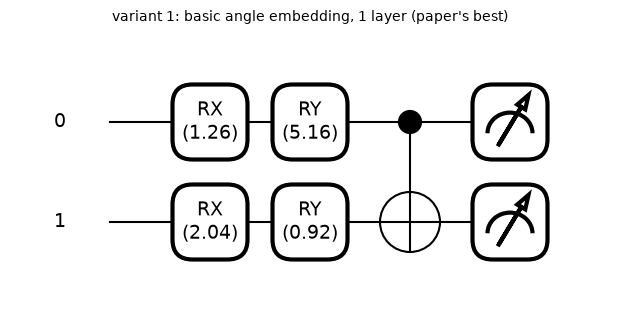

variant 1: basic angle embedding, 1 layer (paper's best)
   qubits = 2 | depth (embedding + VQC) = 3 | gates = 5 | trainable quantum parameters = 2 | measurements: <Z_0>, <Z_1>


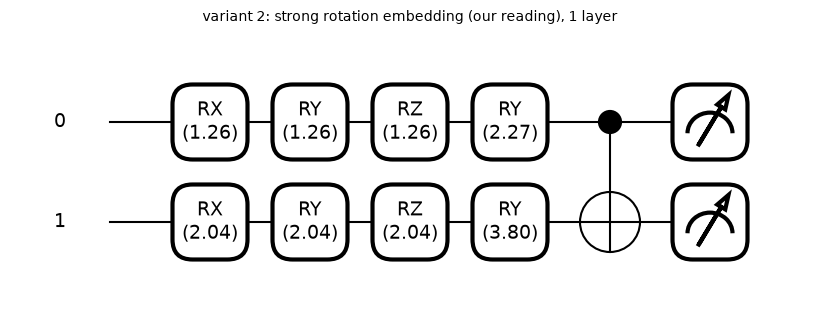

variant 2: strong rotation embedding (our reading), 1 layer
   qubits = 2 | depth (embedding + VQC) = 5 | gates = 9 | trainable quantum parameters = 2 | measurements: <Z_0>, <Z_1>


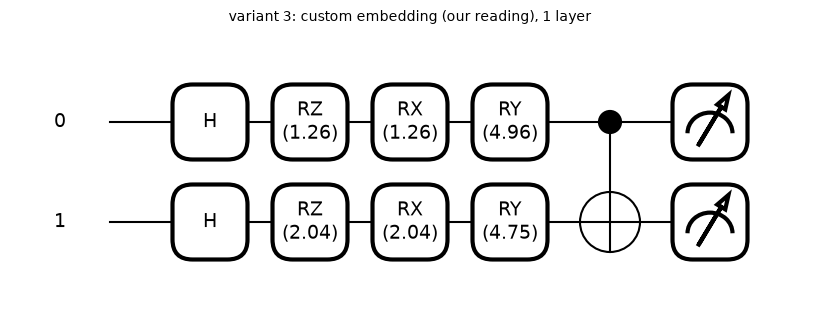

variant 3: custom embedding (our reading), 1 layer
   qubits = 2 | depth (embedding + VQC) = 5 | gates = 9 | trainable quantum parameters = 2 | measurements: <Z_0>, <Z_1>


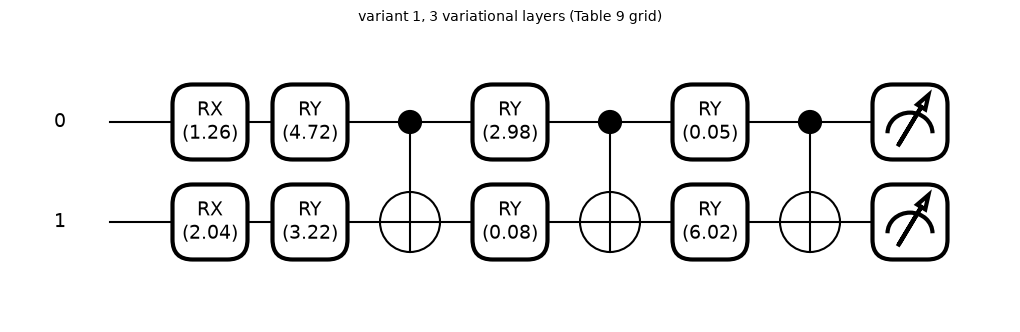

variant 1, 3 variational layers (Table 9 grid)
   qubits = 2 | depth (embedding + VQC) = 7 | gates = 11 | trainable quantum parameters = 6 | measurements: <Z_0>, <Z_1>

classical parameters around the quantum node: 8583 | total trainable parameters of the variant-1 HQCNN: 8585


In [13]:
_x0 = torch.tensor([0.8, 1.3], dtype=torch.float64)                  # an example input, only used to build the drawing
CIRCUITS = {"variant 1: basic angle embedding, 1 layer (paper's best)": (1, 1),
            "variant 2: strong rotation embedding (our reading), 1 layer": (2, 1),
            "variant 3: custom embedding (our reading), 1 layer": (3, 1),
            "variant 1, 3 variational layers (Table 9 grid)": (1, 3)}
fig_list = []
for title, (v, nl) in CIRCUITS.items():
    qn = make_qnode(v, nl)
    w0 = torch.rand(nl, N_QUBITS, dtype=torch.float64) * 2 * np.pi
    fig, ax = qml.draw_mpl(qn, level="device", decimals=2)(_x0, w0)
    fig.suptitle(title, y=1.04, fontsize=10); plt.show()
    res = qml.specs(qn, level="device")(_x0, w0)["resources"]
    print(f"{title}\n   qubits = {N_QUBITS} | depth (embedding + VQC) = {res.depth} | gates = {res.num_gates} | trainable quantum parameters = {nl * N_QUBITS} | measurements: <Z_0>, <Z_1>")
_clf = HQCNN()
print("\nclassical parameters around the quantum node:", sum(p.numel() for n, p in _clf.named_parameters() if n != "qw"),
      "| total trainable parameters of the variant-1 HQCNN:", sum(p.numel() for p in _clf.parameters()))

In [14]:
# Equivalence checks: (1) default.qubit vs lightning.qubit, (2) the QNode vs an independent NumPy state-vector calculation of variant 1.
def numpy_variant1(inputs, weights):
    I2 = np.eye(2); X = np.array([[0, 1], [1, 0]], complex); Y = np.array([[0, -1j], [1j, 0]]); Z = np.diag([1., -1.]).astype(complex)
    rx = lambda t: np.cos(t / 2) * I2 - 1j * np.sin(t / 2) * X
    ry = lambda t: np.cos(t / 2) * I2 - 1j * np.sin(t / 2) * Y
    cnot = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], complex)
    out = []
    for a in inputs:
        psi = np.zeros(4, complex); psi[0] = 1
        psi = np.kron(rx(a[0] * np.pi / 2), rx(a[1] * np.pi / 2)) @ psi
        psi = np.kron(ry(weights[0, 0]), ry(weights[0, 1])) @ psi
        psi = cnot @ psi
        out.append([np.real(psi.conj() @ np.kron(Z, I2) @ psi), np.real(psi.conj() @ np.kron(I2, Z) @ psi)])
    return np.array(out)

_g = torch.Generator().manual_seed(SEED)
_x = torch.rand(64, N_QUBITS, generator=_g, dtype=torch.float64) * 3
_w = torch.rand(1, N_QUBITS, generator=_g, dtype=torch.float64) * 2 * np.pi
_a = torch.stack(make_qnode(1)(_x, _w), -1).numpy()
_b = torch.stack(make_qnode(1, device="lightning.qubit", diff=None)(_x, _w), -1).numpy()
_c = numpy_variant1(_x.numpy(), _w.numpy())
assert np.allclose(_a, _b, atol=1e-8), "default.qubit and lightning.qubit disagree"
assert np.allclose(_a, _c, atol=1e-8), "QNode does not match the independent NumPy simulation"
print("OK: default.qubit == lightning.qubit == NumPy state-vector simulation (max abs diff %.1e)" % max(np.abs(_a - _b).max(), np.abs(_a - _c).max()))

OK: default.qubit == lightning.qubit == NumPy state-vector simulation (max abs diff 4.6e-16)


## 5. Training the binary HQCNN and the classical baselines (paper Section 5.3)

* **HQCNN** (variant 1, 1 layer): Adam, batch size 32, binary cross-entropy, on the 2-D LDA vectors.
* **2-D CNN** (the paper's classical baseline): the Table-6 network trained end-to-end on the scaleograms (already trained above).
* **Dressed classical network**: the same dense layers and the same 2-D LDA input, but the quantum node removed (isolates the contribution of the quantum layer).
* **Random forest / RBF-SVM** on the 24 min-max scaled features and on the same 2-D LDA vectors.

Metrics are computed on the 30 % held-out test split with *attack* as the positive class.

In [15]:
def fit_baselines(Xa, ya, Xb, yb, La, Lb):
    out = {}
    mm = MinMaxScaler().fit(Xa); Za, Zb = mm.transform(Xa), np.clip(mm.transform(Xb), 0, 1)
    for name, mdl, A, B in [("RandomForest (24 features)", RandomForestClassifier(200, random_state=SEED, n_jobs=1), Za, Zb),
                            ("SVC rbf (24 features)", SVC(), Za, Zb),
                            ("RandomForest (2-D LDA)", RandomForestClassifier(200, random_state=SEED, n_jobs=1), La, Lb),
                            ("SVC rbf (2-D LDA)", SVC(), La, Lb)]:
        t0 = time.time(); p = mdl.fit(A, ya).predict(B); out[name] = (metrics(yb, p), time.time() - t0, p)
    return out

RES = {}                                     # name -> (metrics, seconds, predictions) for the main seed
set_all_seeds(SEED)
hq, HQ_HIST, HQ_TIME = train_hqcnn(Ltr, ytr, EPOCHS, SEED)
hq_pred = (hq.predict_logits(Lte) > 0).numpy().astype(int)
RES["HQCNN (variant 1)"] = (metrics(yte, hq_pred), HQ_TIME, hq_pred)
cl, CL_HIST, CL_TIME = train_hqcnn(Ltr, ytr, EPOCHS, SEED, use_quantum=False)
cl_pred = (cl.predict_logits(Lte) > 0).numpy().astype(int)
RES["Dressed classical net (no quantum node)"] = (metrics(yte, cl_pred), CL_TIME, cl_pred)
RES["2-D CNN (end-to-end, paper baseline)"] = (metrics(yte, cnn_pred), CNN_TIME, cnn_pred)
RES.update(fit_baselines(Xtr, ytr, Xte, yte, Ltr, Lte))

tab = pd.DataFrame({k: {**{m: round(v, 2) for m, v in r[0].items()}, "seconds": round(r[1], 1)} for k, r in RES.items()}).T
tab.columns = ["accuracy %", "precision %", "recall %", "F1 %", "train+predict s"]
print(f"Held-out test split ({len(yte)} flows), seed {SEED}, {EPOCHS} HQCNN epochs, {EPOCHS_CNN} CNN epochs:")
tab

Held-out test split (360 flows), seed 42, 12 HQCNN epochs, 8 CNN epochs:


,accuracy %,precision %,recall %,F1 %,train+predict s
HQCNN (variant 1),78.89,79.55,77.78,78.65,276.8
Dressed classical net (no quantum node),78.89,82.10,73.89,77.78,280.5
"2-D CNN (end-to-end, paper baseline)",67.50,63.07,84.44,72.21,743.4
RandomForest (24 features),99.17,99.44,98.89,99.16,1.0
SVC rbf (24 features),85.56,80.48,93.89,86.67,0.1
RandomForest (2-D LDA),80.83,84.47,75.56,79.77,1.0
SVC rbf (2-D LDA),79.17,82.21,74.44,78.13,0.0


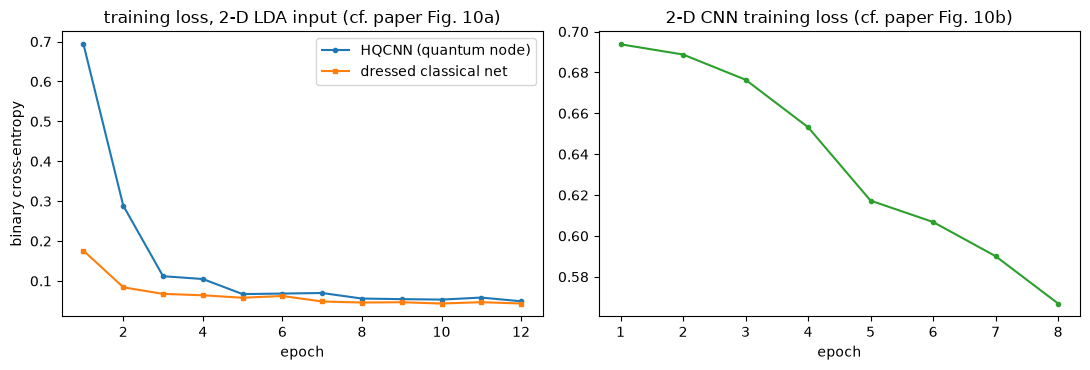

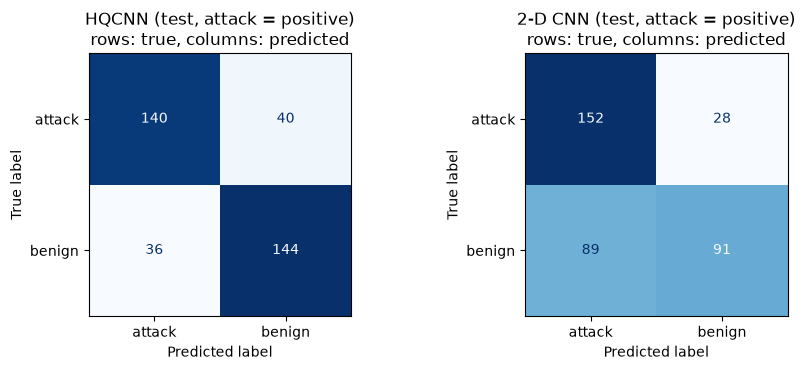

In [16]:
# Fig. 10 (loss curves) and Fig. 11 (confusion matrices) of the paper
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(range(1, len(HQ_HIST) + 1), HQ_HIST, "-o", ms=3, label="HQCNN (quantum node)")
ax[0].plot(range(1, len(CL_HIST) + 1), CL_HIST, "-s", ms=3, label="dressed classical net")
ax[0].set_title("training loss, 2-D LDA input (cf. paper Fig. 10a)"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("binary cross-entropy"); ax[0].legend()
ax[1].plot(range(1, len(CNN_HIST) + 1), CNN_HIST, "-o", ms=3, color="tab:green")
ax[1].set_title("2-D CNN training loss (cf. paper Fig. 10b)"); ax[1].set_xlabel("epoch")
cm_h = confusion_matrix(yte, hq_pred, labels=[1, 0]); cm_c = confusion_matrix(yte, cnn_pred, labels=[1, 0])
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, (cmx, t) in zip(ax, [(cm_h, "HQCNN"), (cm_c, "2-D CNN")]):
    ConfusionMatrixDisplay(cmx, display_labels=["attack", "benign"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{t} (test, attack = positive)\nrows: true, columns: predicted")
plt.tight_layout(); plt.show()

## 6. Circuit variants, layers and shots (paper Tables 7 and 9)

**Table 7**: variants 1-3 with one layer, evaluated with 1000 shots on `lightning.qubit` (the training itself uses the exact simulator, a CHOICE explained above).
**Table 9**: `n_layers` 1 to 3, evaluated with 500 and 1000 shots on `lightning.qubit` (the "AWS SV1" column cannot be reproduced without AWS Braket).
Here every model is trained on the same 2-D LDA vectors of the main seed.

In [17]:
def eval_shots(model, L, y, shots, variant=None):
    """Test accuracy / metrics with finite-shot sampling on lightning.qubit (weights taken from the trained model)."""
    qn = make_qnode(model.variant, model.qw.shape[0], model.n_q, device="lightning.qubit", shots=shots, diff=None)
    p = (model.predict_logits(L, qnode=qn) > 0).numpy().astype(int)
    return metrics(y, p)

T7 = {}
for v in (1, 2, 3):
    if v == 1:
        m, h, tsec = hq, HQ_HIST, HQ_TIME
    else:
        m, h, tsec = train_hqcnn(Ltr, ytr, EPOCHS, SEED, variant=v)
    T7[v] = dict(analytic=metrics(yte, (m.predict_logits(Lte) > 0).numpy().astype(int)), shots1000=eval_shots(m, Lte, yte, 1000), seconds=tsec)
t7 = pd.DataFrame({f"variant {v}": {"acc (1000 shots)": r["shots1000"]["acc"], "prec": r["shots1000"]["prec"], "rec": r["shots1000"]["rec"], "F1": r["shots1000"]["f1"],
                                   "acc (exact)": r["analytic"]["acc"], "train s": r["seconds"]} for v, r in T7.items()}).round(2)
print("Our Table 7 (n_layers = 1, n_shots = 1000):"); t7

Our Table 7 (n_layers = 1, n_shots = 1000):


,variant 1,variant 2,variant 3
acc (1000 shots),78.33,78.61,78.89
prec,78.98,81.21,81.33
rec,77.22,74.44,75.00
F1,78.09,77.68,78.03
acc (exact),78.89,78.06,78.61
train s,276.79,241.39,37.14


In [18]:
T9 = {}
for nl in (1, 2, 3):
    m, h, tsec = train_hqcnn(Ltr, ytr, EPOCHS_GRID, SEED, n_layers=nl)
    T9[nl] = {"exact": metrics(yte, (m.predict_logits(Lte) > 0).numpy().astype(int))["acc"],
              "500 shots": eval_shots(m, Lte, yte, 500)["acc"], "1000 shots": eval_shots(m, Lte, yte, 1000)["acc"]}
t9 = pd.DataFrame(T9).T.round(2); t9.index.name = "n_layers"
print(f"Our Table 9 (Lightning simulator, test accuracy %, {EPOCHS_GRID} epochs per cell):"); t9

Our Table 9 (Lightning simulator, test accuracy %, 8 epochs per cell):


,exact,500 shots,1000 shots
n_layers,,,
1,78.89,76.67,78.06
2,78.61,78.06,78.06
3,79.72,78.61,80.00


## 7. Several seeds and k-fold cross-validation (paper Table 8)

Table 8 compares the HQCNN with the 2-D CNN on every fold of a 10-fold cross-validation. Here the whole pipeline (min-max, scaleograms, CNN, LDA, HQCNN) is **re-fitted inside each training fold** so no information from the validation fold leaks;
the folds are stratified and drawn from the same balanced sample.

In [19]:
# (a) repeat the held-out experiment over seeds (the main seed is reused)
SEED_RES = {SEED: dict(hq=RES["HQCNN (variant 1)"][0], cnn=RES["2-D CNN (end-to-end, paper baseline)"][0], cl=RES["Dressed classical net (no quantum node)"][0])}
for sd in SEEDS:
    if sd == SEED: continue
    tr, te = split_for_seed(sd)
    f = build_features(SDN_X.values[tr], SDN_Y[tr], SDN_X.values[te], sd, EPOCHS_CNN)
    m, _, _ = train_hqcnn(f["La"], SDN_Y[tr], EPOCHS, sd)
    c, _, _ = train_hqcnn(f["La"], SDN_Y[tr], EPOCHS, sd, use_quantum=False)
    SEED_RES[sd] = dict(hq=metrics(SDN_Y[te], (m.predict_logits(f["Lb"]) > 0).numpy().astype(int)), cnn=metrics(SDN_Y[te], f["cnn_pred"]),
                        cl=metrics(SDN_Y[te], (c.predict_logits(f["Lb"]) > 0).numpy().astype(int)))
seed_tab = pd.DataFrame({k: {sd: r[k]["acc"] for sd, r in SEED_RES.items()} for k in ("hq", "cnn", "cl")})
seed_tab.columns = ["HQCNN acc %", "2-D CNN acc %", "dressed classical acc %"]
print("test accuracy per seed:"); print(seed_tab.round(2).to_string())
print("mean +- std over %d seed(s):" % len(SEEDS), {c: f"{seed_tab[c].mean():.2f} +- {seed_tab[c].std(ddof=0):.2f}" for c in seed_tab.columns})

test accuracy per seed:
    HQCNN acc %  2-D CNN acc %  dressed classical acc %
42        78.89           67.5                    78.89
mean +- std over 1 seed(s): {'HQCNN acc %': '78.89 +- 0.00', '2-D CNN acc %': '67.50 +- 0.00', 'dressed classical acc %': '78.89 +- 0.00'}


fold 1/3: HQCNN 79.75  CNN 66.50   (336 s elapsed)


fold 2/3: HQCNN 89.25  CNN 65.00   (664 s elapsed)


fold 3/3: HQCNN 79.75  CNN 59.00   (826 s elapsed)
      hqcnn   cnn
fold             
1     79.75  66.5
2     89.25  65.0
3     79.75  59.0
mean  82.92  63.5


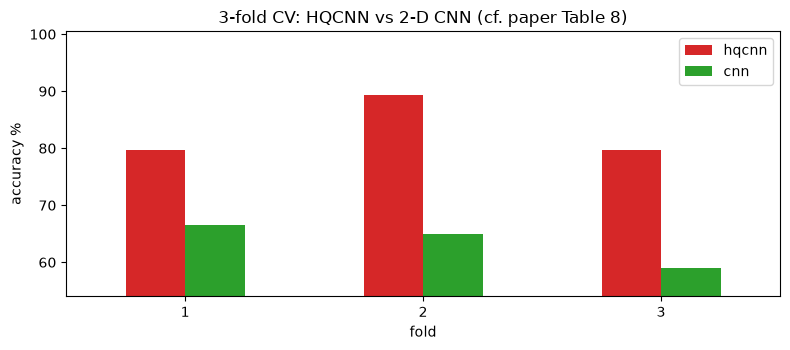

In [20]:
# (b) k-fold cross-validation (Table 8). Transforms are fitted on the training part of each fold only.
idx_all = balanced_sample(SDN_Y, N_PER_CLASS, SEED)
Xall, yall = SDN_X.values[idx_all], SDN_Y[idx_all]
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
CV = []
t0 = time.time()
for k, (a, b) in enumerate(skf.split(Xall, yall), 1):
    f = build_features(Xall[a], yall[a], Xall[b], SEED + k, EPOCHS_CV)
    m, _, _ = train_hqcnn(f["La"], yall[a], EPOCHS_CV, SEED + k)
    ph = (m.predict_logits(f["Lb"]) > 0).numpy().astype(int)
    CV.append(dict(fold=k, hqcnn=100 * accuracy_score(yall[b], ph), cnn=100 * accuracy_score(yall[b], f["cnn_pred"])))
    print(f"fold {k}/{K_FOLDS}: HQCNN {CV[-1]['hqcnn']:.2f}  CNN {CV[-1]['cnn']:.2f}   ({time.time() - t0:.0f} s elapsed)")
cv = pd.DataFrame(CV).set_index("fold")
cv.loc["mean"] = cv.mean()
print(cv.round(2).to_string())
fig, ax = plt.subplots(figsize=(8, 3.6))
cv.iloc[:-1].plot.bar(ax=ax, rot=0, color=["tab:red", "tab:green"]); ax.set_ylabel("accuracy %"); ax.set_title(f"{K_FOLDS}-fold CV: HQCNN vs 2-D CNN (cf. paper Table 8)")
ax.set_ylim(max(0, cv.iloc[:-1].values.min() - 5), 100.5); plt.tight_layout(); plt.show()

### Ablation (not in the paper): heavy-tailed flow features

Packet and byte counters in the SDN data span many orders of magnitude, so plain min-max scaling (Eq. 1) squeezes most flows into a tiny corner of [0, 1] and the scaleograms of different flows look alike.
As a control we repeat the main experiment with a signed `log1p` applied to the 24 features *before* the same min-max / wavelet / CNN / LDA / HQCNN pipeline. Everything else is unchanged and fitted on the training split only.

In [21]:
def slog(X): return np.sign(X) * np.log1p(np.abs(X))
featL = build_features(slog(Xtr), ytr, slog(Xte), SEED, EPOCHS_CNN)
mL, _, _ = train_hqcnn(featL["La"], ytr, EPOCHS, SEED)
cL, _, _ = train_hqcnn(featL["La"], ytr, EPOCHS, SEED, use_quantum=False)
ABL = {"HQCNN, log1p input": metrics(yte, (mL.predict_logits(featL["Lb"]) > 0).numpy().astype(int)),
       "dressed classical net, log1p input": metrics(yte, (cL.predict_logits(featL["Lb"]) > 0).numpy().astype(int)),
       "2-D CNN, log1p input": metrics(yte, featL["cnn_pred"])}
ABL_df = pd.DataFrame(ABL).T.round(2); ABL_df.columns = ["accuracy %", "precision %", "recall %", "F1 %"]
print("Ablation: signed log1p before min-max (held-out test split, same budgets):"); ABL_df

Ablation: signed log1p before min-max (held-out test split, same budgets):


,accuracy %,precision %,recall %,F1 %
"HQCNN, log1p input",74.72,77.30,70.00,73.47
"dressed classical net, log1p input",75.56,77.06,72.78,74.86
"2-D CNN, log1p input",71.94,65.99,90.56,76.35


              precision    recall  f1-score   support

      benign     0.7826    0.8000    0.7912       180
      attack     0.7955    0.7778    0.7865       180

    accuracy                         0.7889       360
   macro avg     0.7890    0.7889    0.7889       360
weighted avg     0.7890    0.7889    0.7889       360



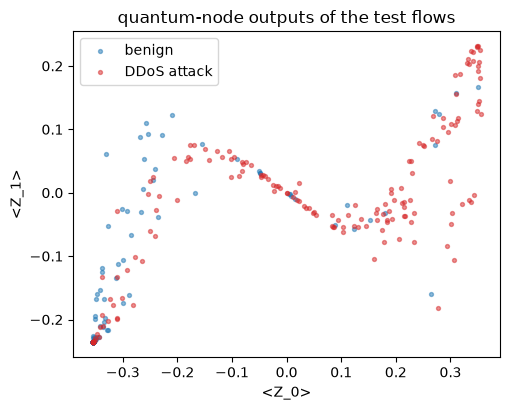

In [22]:
# Classification report of the HQCNN on the held-out split, and a look at what the quantum layer outputs.
from sklearn.metrics import classification_report
print(classification_report(yte, hq_pred, target_names=["benign", "attack"], digits=4))
with torch.no_grad():
    qfeat = hq.features(torch.tensor(Lte)).numpy()
fig, ax = plt.subplots(figsize=(5.2, 4.2))
for lab, col, name in [(0, "tab:blue", "benign"), (1, "tab:red", "DDoS attack")]:
    ax.scatter(qfeat[yte == lab, 0], qfeat[yte == lab, 1], s=8, alpha=0.5, c=col, label=name)
ax.set_xlabel("<Z_0>"); ax.set_ylabel("<Z_1>"); ax.set_title("quantum-node outputs of the test flows"); ax.legend(); plt.tight_layout(); plt.show()

## 8. Android malware half (multi-class HQCNN): ready to run, data not available here

The same pipeline is used with a multi-class head: scaleogram (3 DWT levels, `bior6.8`, Morlet CWT) -> CNN (one output per class) -> two LDA tracks with `n - 1` components each -> dense input layer -> `ANDMAL_QUBITS`-qubit
circuit (angle embedding, `BasicEntanglerLayers`, `<Z_k>` on every qubit) -> three Dense(64) -> `n`-way output (softmax / cross-entropy).
The three class sets of the paper's Table 4 are: 15 classes (all), 14 classes (without `NoCategory`) and 12 classes (without `Benign`, `Zeroday` and `NoCategory`), 800 apps per class.

If `ANDMAL_PATH` is `None` (the case here), the cell below only prints what is missing. If you supply the CIC static CSV it trains the multi-class HQCNN and the CNN baseline for the three class sets and prints accuracy next to the paper's numbers.
This code path **has not been executed on the real Android data** by the author of this notebook (the data cannot be obtained without the CIC form); its machinery (images, CNN, LDA tracks, multi-class dressed circuit) was exercised on a
different, real, three-class problem built from the SDN flows (protocol TCP / UDP / ICMP) during development, which is not reported here.

In [23]:
import re
ANDMAL_PAPER = {15: 93.56, 14: 94.38, 12: 95.13}                 # Table 12
ANDMAL_DROP  = {15: [], 14: ["nocategory"], 12: ["benign", "zeroday", "nocategory"]}     # Table 4 columns
_norm = lambda s: re.sub("[^a-z]", "", str(s).lower())

def run_multiclass(X, y, names, seed, epochs_cnn, epochs_hq, image_kw, n_q, label=""):
    """Held-out 70/30 experiment for n classes: scaleogram CNN baseline and multi-class HQCNN. X: raw feature matrix, y: integer labels."""
    n = len(names)
    tr, te = train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=seed)
    f = build_features(X[tr], y[tr], X[te], seed, epochs_cnn, image_kw=image_kw, n_classes=n)
    set_all_seeds(seed)
    m = HQCNN(n_in=f["La"].shape[1], n_q=n_q, n_out=n)
    t0 = time.time(); hist = fit_torch(m, f["La"], y[tr], epochs_hq, LR_HQ, seed=seed, loss="ce")
    ph = m.predict_logits(f["Lb"]).argmax(1).numpy()
    return dict(label=label, hq_acc=100 * accuracy_score(y[te], ph), cnn_acc=100 * accuracy_score(y[te], f["cnn_pred"]),
                hq_pred=ph, y_test=y[te], hist=hist, seconds=time.time() - t0)

ANDROID_RESULTS = {}
if ANDMAL_PATH is not None and os.path.exists(ANDMAL_PATH):
    raw = pd.read_csv(ANDMAL_PATH)                                  # may be large: reduce with usecols / chunks if memory is short
    assert ANDMAL_LABEL_COL in raw.columns, f"label column {ANDMAL_LABEL_COL!r} not found; columns start with {list(raw.columns[:8])}"
    num = raw.drop(columns=[ANDMAL_LABEL_COL]).select_dtypes("number").replace([np.inf, -np.inf], np.nan).fillna(0)
    lab = raw[ANDMAL_LABEL_COL].map(_norm)
    print("categories in the file:", lab.value_counts().to_dict())
    img_kw = dict(level=ANDMAL_LEVELS, n_scales=ANDMAL_IMG, width=ANDMAL_IMG)
    for n_cls, drop in ANDMAL_DROP.items():
        keep = ~lab.isin(drop)
        cats = sorted(lab[keep].unique())
        r_ = np.random.default_rng(SEED)
        idx = np.concatenate([r_.choice(np.where((lab == c).values)[0], min(ANDMAL_N_PER_CLASS, int((lab == c).sum())), replace=False) for c in cats])
        yi = lab.iloc[idx].map({c: i for i, c in enumerate(cats)}).values.astype(int)
        print(f"{n_cls}-class version -> {len(cats)} categories found, {len(idx)} apps")
        ANDROID_RESULTS[n_cls] = run_multiclass(num.values[idx].astype(np.float32), yi, cats, SEED, EPOCHS_CNN, EPOCHS, img_kw, ANDMAL_QUBITS, label=f"{n_cls}-class")
        r = ANDROID_RESULTS[n_cls]
        print(f"   HQCNN accuracy {r['hq_acc']:.2f} % | 2-D CNN accuracy {r['cnn_acc']:.2f} % | paper HQCNN {ANDMAL_PAPER[n_cls]} %")
else:
    print("Android half skipped: no CCCS-CIC-AndMal2020 static file supplied.")
    print("Needed to run it: the static feature CSV (9,503 numeric columns + category column) from https://www.unb.ca/cic/datasets/andmal2020.html (registration form), then set ANDMAL_PATH / ANDMAL_LABEL_COL.")

Android half skipped: no CCCS-CIC-AndMal2020 static file supplied.
Needed to run it: the static feature CSV (9,503 numeric columns + category column) from https://www.unb.ca/cic/datasets/andmal2020.html (registration form), then set ANDMAL_PATH / ANDMAL_LABEL_COL.


## 9. Side by side with the paper, claim by claim

Verdict rule: **reproduced** when within 2 accuracy points (0.02 F1) of the paper's value, **exceeded** when higher by more than that, **not reached** when lower by more than that,
**cannot be checked** when the experiment needs hardware, services or data that are not available here.

In [24]:
def verdict(paper, ours, tol=2.0):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked"
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded (+%.1f)" % d if d > 0 else "not reached (%.1f)" % d)

v1 = T7[1]["shots1000"]; hq_m = RES["HQCNN (variant 1)"][0]
cv_hq, cv_cnn = cv.loc["mean", "hqcnn"], cv.loc["mean", "cnn"]
rows = [
 ("Table 7  V1 accuracy (1000 shots)", 99.86, v1["acc"]), ("Table 7  V1 precision", 99.85, v1["prec"]), ("Table 7  V1 recall", 100.0, v1["rec"]), ("Table 7  V1 F1", 99.88, v1["f1"]),
 ("Table 7  V2 accuracy", 97.43, T7[2]["shots1000"]["acc"]), ("Table 7  V3 accuracy", 97.12, T7[3]["shots1000"]["acc"]),
 ("Table 8  HQCNN mean CV accuracy", 99.86, cv_hq), ("Table 8  2-D CNN mean CV accuracy", 86.80, cv_cnn),
 ("Table 9  Lightning n_layers=1, 500 shots", 99.96, T9[1]["500 shots"]), ("Table 9  Lightning n_layers=1, 1000 shots", 99.76, T9[1]["1000 shots"]),
 ("Table 9  Lightning n_layers=2, 500 shots", 99.78, T9[2]["500 shots"]), ("Table 9  Lightning n_layers=2, 1000 shots", 99.94, T9[2]["1000 shots"]),
 ("Table 9  Lightning n_layers=3, 500 shots", 99.87, T9[3]["500 shots"]), ("Table 9  Lightning n_layers=3, 1000 shots", 99.65, T9[3]["1000 shots"]),
 ("Table 9  AWS SV1 simulator (6 cells)", 99.86, None), ("Table 10 HQCNN on Lucy / Aspen-M-3 QPU", 99.56, None), ("Table 10 2-D CNN baseline", 91.0, RES["2-D CNN (end-to-end, paper baseline)"][0]["acc"]),
]
for n_cls, p in ANDMAL_PAPER.items():
    rows.append((f"Table 12 Android HQCNN, {n_cls} classes", p, ANDROID_RESULTS[n_cls]["hq_acc"] if n_cls in ANDROID_RESULTS else None))
rows.append(("Table 11 Android 2-D CNN, 12 classes (mean CV)", 78.94, None))
cmp_df = pd.DataFrame([(a, b, (round(c, 2) if c is not None else "-"), verdict(b, c)) for a, b, c in rows], columns=["claim", "paper %", "this notebook %", "verdict"])
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 70)
cmp_df

,claim,paper %,this notebook %,verdict
0,Table 7 V1 accuracy (1000 shots),99.86,78.33,not reached (-21.5)
1,Table 7 V1 precision,99.85,78.98,not reached (-20.9)
2,Table 7 V1 recall,100.00,77.22,not reached (-22.8)
3,Table 7 V1 F1,99.88,78.09,not reached (-21.8)
4,Table 7 V2 accuracy,97.43,78.61,not reached (-18.8)
5,Table 7 V3 accuracy,97.12,78.89,not reached (-18.2)
6,Table 8 HQCNN mean CV accuracy,99.86,82.92,not reached (-16.9)
7,Table 8 2-D CNN mean CV accuracy,86.80,63.5,not reached (-23.3)
8,"Table 9 Lightning n_layers=1, 500 shots",99.96,76.67,not reached (-23.3)
9,"Table 9 Lightning n_layers=1, 1000 shots",99.76,78.06,not reached (-21.7)


In [25]:
# Qualitative claims
cm_h = confusion_matrix(yte, hq_pred, labels=[0, 1]); cm_c = confusion_matrix(yte, cnn_pred, labels=[0, 1])
fp_h, fn_h = cm_h[0, 1], cm_h[1, 0]; fp_c = cm_c[0, 1]
share_c = 100 * fp_c / cm_c[0].sum()
hq_beats_cnn_folds = int((cv.iloc[:-1]["hqcnn"] > cv.iloc[:-1]["cnn"]).sum())
q = [
 ("HQCNN beats the 2-D CNN on every CV fold (Table 8)", f"HQCNN better on {hq_beats_cnn_folds} of {K_FOLDS} folds", "reproduced" if hq_beats_cnn_folds == K_FOLDS else "not reached"),
 ("HQCNN confusion matrix without errors (Fig. 11a)", f"{fp_h} false positives, {fn_h} false negatives on {len(yte)} test flows", "reproduced" if fp_h + fn_h == 0 else "not reached"),
 ("2-D CNN misclassifies about 19 % of normal traffic (Fig. 11b)", f"{share_c:.1f} % of benign test flows flagged as attack", "reproduced" if abs(share_c - 19) <= 5 else "different (%.1f %%)" % share_c),
 ("Variant 1 is the best of the three embeddings (Table 7)", "acc V1/V2/V3 = %.2f / %.2f / %.2f" % (T7[1]["shots1000"]["acc"], T7[2]["shots1000"]["acc"], T7[3]["shots1000"]["acc"]),
  "reproduced" if T7[1]["shots1000"]["acc"] >= max(T7[2]["shots1000"]["acc"], T7[3]["shots1000"]["acc"]) else "not reached"),
 ("Quantum node is what makes the difference", "HQCNN %.2f vs dressed classical net (no quantum node) %.2f" % (hq_m["acc"], RES["Dressed classical net (no quantum node)"][0]["acc"]),
  "the paper does not run this control; difference within noise" if abs(hq_m["acc"] - RES["Dressed classical net (no quantum node)"][0]["acc"]) < 1.5 else "differs"),
 ("A simple classical model on the raw 24 features", "RF %.2f %%, SVC %.2f %%" % (RES["RandomForest (24 features)"][0]["acc"], RES["SVC rbf (24 features)"][0]["acc"]), "context for the 99.86 % claim"),
]
pd.DataFrame(q, columns=["claim", "this notebook", "verdict"])

,claim,this notebook,verdict
0,HQCNN beats the 2-D CNN on every CV fold (Table 8),HQCNN better on 3 of 3 folds,reproduced
1,HQCNN confusion matrix without errors (Fig. 11a),"36 false positives, 40 false negatives on 360 test flows",not reached
2,2-D CNN misclassifies about 19 % of normal traffic (Fig. 11b),49.4 % of benign test flows flagged as attack,different (49.4 %)
3,Variant 1 is the best of the three embeddings (Table 7),acc V1/V2/V3 = 78.33 / 78.61 / 78.89,not reached
4,Quantum node is what makes the difference,HQCNN 78.89 vs dressed classical net (no quantum node) 78.89,the paper does not run this control; difference within noise
5,A simple classical model on the raw 24 features,"RF 99.17 %, SVC 85.56 %",context for the 99.86 % claim


## Reading the paper critically

* **The headline contrast is not a like-for-like comparison.** HQCNN 99.86 % vs CNN 86.8 % compares a model fed with LDA features against a plain CNN. In this run a random forest on the 24 raw flow features reaches 99.2 % in about a second
  (table in section 5), i.e. the data set is easy for ordinary classifiers. The fair control for the quantum layer is the "dressed classical network" (same pipeline, quantum node removed); the paper does not report it, and here it ties the HQCNN (78.9 % each).
* **The wavelet-image detour loses information at these budgets.** Turning 24 numbers into a 12 x 12 colour image, training a CNN for 8 epochs on 840 flows and compressing to 2 LDA numbers gave a 2-D CNN of 67.5 % and an HQCNN of 78.9 %, far below the raw-feature random forest.
  The signed-`log1p` ablation did not help (HQCNN 74.7 %). The paper trains for 100 epochs on 2,800 flows, which this run does not; so the gap to 99.86 % is evidence that the pipeline is under-specified or budget-hungry, not a refutation of the paper. A full-budget run (configuration cell) is needed to settle it.
* **Where the information is.** After the LDA step every later stage only sees two numbers per flow, so the quantum node can only re-map two numbers; any advantage would have to come from that re-mapping, which the classical control does not show here.
* **Underspecified experiment.** Learning rate, wavelet for the SDN data, how the "concatenated 2-D LDA vector" is built, what the circuits of variants 2 and 3 are, and what exactly is cross-validated are not stated, so numbers can only be matched through choices
  (marked `# CHOICE` and listed in the table). The 24 "features" of the data set include IP addresses, a time stamp (`dt`) and a switch id that identify the simulation run rather than the attack.
* **Cross-validation and leakage.** With flows from the same simulation run in both training and validation folds, a random split is optimistic; a split by topology / time would be a harder test. Here every transform is re-fitted per fold, which the paper does not say it does. The CV here has 3 folds, not 10.
* **Real QPU results.** Table 10 reports 99.56 % on two QPUs with the same circuit that gives 99.86 % on a simulator; a 2-qubit, 1-layer circuit is shallow, so small hardware noise is plausible, but Table 10 cannot be repeated here (no hardware; the Rigetti Aspen-M-3 device is no longer offered).
* **Android half.** The multi-class claim (93.56 / 94.38 / 95.13 %) depends on a class-balanced subset of 800 apps per category; the 12-class set also drops Benign, which makes it a different problem from the 15-class set. Only the data owner's registration form separates a reader from checking it.
* **Reproduction here.** Budgets are much smaller than the paper's (see the configuration cell), there is one seed, and the exact differentiable simulator replaces sampling during training. Read the verdict table accordingly.

## Exercises

1. Set `FAST_MODE = False` (about 100 epochs, 10 folds). Does the HQCNN accuracy move towards the paper's value? How much of the gap is closed by more CNN epochs (`EPOCHS_CNN`) rather than more HQCNN epochs?
2. Remove the CNN track and use only LDA of the raw 24 min-max features as the 2-D input (or only the first LDA component). Compare HQCNN, dressed classical network and RBF-SVM. Where does the information come from?
3. Re-implement variants 2 and 3 from your own reading of the paper's Figs. 7-8 and see whether the ordering V1 > V2 > V3 survives. Does it survive a second seed?
4. Add a depolarising noise channel (`default.mixed`, `qml.DepolarizingChannel`) after every gate with probability 0.001-0.02 and plot accuracy against the noise level. How noisy can the 2-qubit circuit be before the accuracy drops?
5. Register with the CIC, download the CCCS-CIC-AndMal2020 static features, set `ANDMAL_PATH`, and run section 8. Which categories (Ransomware, Banker, Trojan?) are confused most? Compare with the paper's Table 11.